<a href="https://colab.research.google.com/github/Sayak-coder/HateSpeech-detection/blob/main/5_models_classification_report_(IT).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install fasttext

In [49]:
!pip install simplemma

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.0/19.0 MB 27.8 MB/s  0:00:00


In [3]:
!pip install nltk

In [4]:
!pip install gensim

In [50]:
import pandas as pd
import numpy as np
import nltk
# from nltk.stem import WordNetLemmatizer
from simplemma import lemmatize
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import re
import gensim
from gensim.models import Word2Vec
import gensim.downloader as api

In [11]:
df_it = pd.read_csv('/content/StereoQueerEval_IT_training.tsv', sep='\t')
df_it.head()

,StereoQueerEval_id,yt_title,yt_description,yt_comment,stereotype,hate_speech,target
0,training_IT_0001,"Nivan transgender a 17 anni: ""Il mio percorso ...",Nivan è un ragazzo transgender Ftm di soli 17 ...,Sono transgender ma ho paura di dirlo ai miei ...,no,no,none
1,training_IT_0002,"Casillas annuncia di essere gay, poi parla di ...","Travolto dalle polemiche, Casillas è stato cos...",E cosa sarà mai guardate cosa succede nel mond...,no,yes_implicit,group_g
2,training_IT_0003,Schlein: «Con governo Meloni l’Italia è scivol...,«Sono sempre felice quando c’è il riconoscimen...,Ma fate silenzio il gay pride e finito ora and...,yes,yes_explicit,group_lgbtqia+
3,training_IT_0004,"Olimpiadi Parigi 2024, la pugile Imane Khelif ...",Dopo che Angela Carini alle Olimpiadi di Parig...,Donna Trans NON ESISTE! Un uomo non puo` diven...,yes,yes_explicit,group_t
4,training_IT_0005,"Roma Pride 2018, l'inno ""Ma che ti importa"": ""...",Sabato 9 giugno il Roma Pride scende in piazza...,Allora che vi importa se uno dice che prenderl...,no,yes_explicit,"group_g,lgbtqia+"


In [12]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [13]:
df = df_it[['yt_comment','stereotype']]

In [14]:
df.head()

,yt_comment,stereotype
0,Sono transgender ma ho paura di dirlo ai miei ...,no
1,E cosa sarà mai guardate cosa succede nel mond...,no
2,Ma fate silenzio il gay pride e finito ora and...,yes
3,Donna Trans NON ESISTE! Un uomo non puo` diven...,yes
4,Allora che vi importa se uno dice che prenderl...,no


In [15]:
sentences=[]
for i in range(len(df['yt_comment'])):
  sentence = nltk.sent_tokenize(df['yt_comment'][i])
  sentences.append(sentence)
sentences

[['Sono transgender ma ho paura di dirlo ai miei perché come già so non mi supporterebbero'],
 ['E cosa sarà mai guardate cosa succede nel mondo  sveglia !', '!', '!'],
 ['Ma fate silenzio il gay pride e finito ora andate a lavorare'],
 ['Donna Trans NON ESISTE!',
  'Un uomo non puo` diventare donna e una donna non puo` diventare un uomo anche se si fanno operazioni chirurgiche.',
  'I sentimenti non contano.',
  'Questo soggetto e` assurdo e irrilevante.'],
 ['Allora che vi importa se uno dice che prenderlo nel culo fa male ed è antifisiologico?',
  'Che vi importa se si dice che i rapporti anali non sono sesso ?',
  'E che due uomini non possono fare una famiglia e adottare figli ?',
  'Che vi importa ?'],
 ['Le lobby lgbt cariche di odio e le persone omosessuali sono cose ben ben diverse.',
  'Ancora con sto stereotipo sciocco degli omosessuali che sono tutti a sinistra?',
  'Ma aggiornatevi!',
  '!'],
 ['Che palle.',
  'Ognuno è libero di fare ciò che vuole.',
  'È una cosa che rig

In [54]:
corpus=[]

stop_words = set(stopwords.words('italian'))

for i in range(len(sentences)):
    full_text = ' '.join(sentences[i])
    review = re.sub('[^a-zA-Zàèéìòù]', ' ', full_text)
    review = review.lower()

    words = word_tokenize(review)
    words = [lemmatize(word, lang='it') for word in words if word not in stop_words]

    corpus.append(' '.join(words))

In [55]:
corpus[1]

'travolgere polemica casillas essere costringere cancellare tweet dichiarare omosessuale scritto dissimulare gossip vita sentimentale pensare modello esempio delusione scherzare cosa colpa hacker scusare messaggio ex portiere casillas annunciare essere gay poi parlare hacker scusa scherzare idiota url rimanere aggiornare url attivare correttamente notifica qualsiasi smartphone url commentare ultimo notizia entrare community url channel giornale indipendente sociale partecipativo seguire live reportage inchiesta storia videonews partecipare informazione rimanere connesso channel facebook url instagram url twitter url tiktok url url'

In [12]:
wv = api.load('word2vec-google-news-300')

[==================================================] 100.0% 1662.8/1662.8MB downloaded


In [1]:
from huggingface_hub import hf_hub_download
import fasttext

path = hf_hub_download("facebook/fasttext-it-vectors", "model.bin")
wv_it = fasttext.load_model(path)

In [56]:
sent_vectors = []

vector_size = wv_it.get_dimension()

for sentence in corpus:
    vecs = [wv_it[word] for word in sentence.split()]
    if vecs:
        sent_vec = np.mean(vecs, axis=0)
    else:
        sent_vec = np.zeros(vector_size)
    sent_vectors.append(sent_vec)

X = np.array(sent_vectors)

In [57]:
X

array([[ 0.01891615, -0.01385991,  0.00395118, ..., -0.02179315,
         0.0027979 , -0.00566312],
       [ 0.01325981,  0.0109299 ,  0.03325931, ..., -0.02685107,
         0.01309034, -0.00143624],
       [ 0.02496078, -0.00862176,  0.00885732, ..., -0.00629057,
        -0.00113309, -0.01311493],
       ...,
       [ 0.00027345,  0.00202902,  0.05289146, ..., -0.02828402,
         0.00185197, -0.00213731],
       [ 0.01906046,  0.00497586,  0.02455887, ..., -0.03289919,
         0.00939036, -0.00208683],
       [ 0.02849967, -0.01767418,  0.01264638, ..., -0.01086925,
        -0.02281502, -0.00805411]], shape=(2400, 300), dtype=float32)

In [58]:
y = df['stereotype'].map({'no':0,'yes':1})
y.head()

,stereotype
0,0
1,0
2,1
3,1
4,0


In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=45)

In [60]:
X_train.shape, X_test.shape

((1920, 300), (480, 300))

Logistic Regression

In [61]:
from sklearn.metrics import accuracy_score, classification_report

In [62]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.75
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       359
           1       1.00      0.01      0.02       121

    accuracy                           0.75       480
   macro avg       0.87      0.50      0.44       480
weighted avg       0.81      0.75      0.64       480



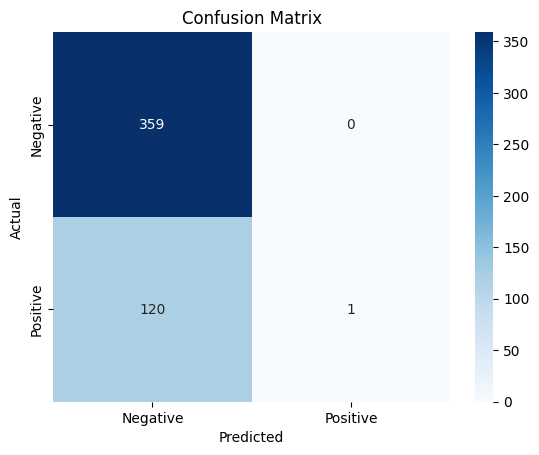

In [63]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

RandomForestClassifier


In [64]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.68125
              precision    recall  f1-score   support

           0       0.77      0.82      0.79       359
           1       0.33      0.26      0.29       121

    accuracy                           0.68       480
   macro avg       0.55      0.54      0.54       480
weighted avg       0.66      0.68      0.67       480



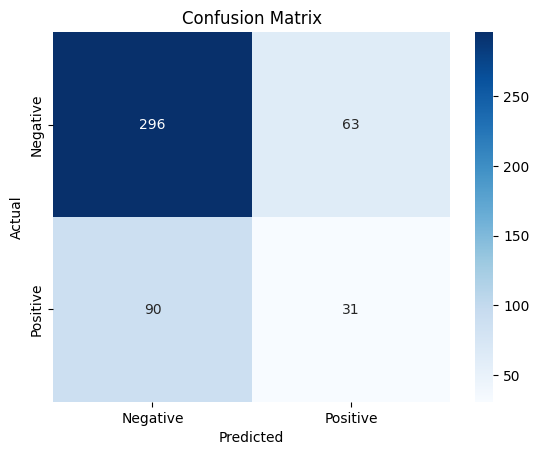

In [65]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

XGBoost

In [66]:
from xgboost import XGBClassifier

model = XGBClassifier()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.7041666666666667
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       359
           1       0.37      0.26      0.30       121

    accuracy                           0.70       480
   macro avg       0.57      0.56      0.56       480
weighted avg       0.67      0.70      0.68       480



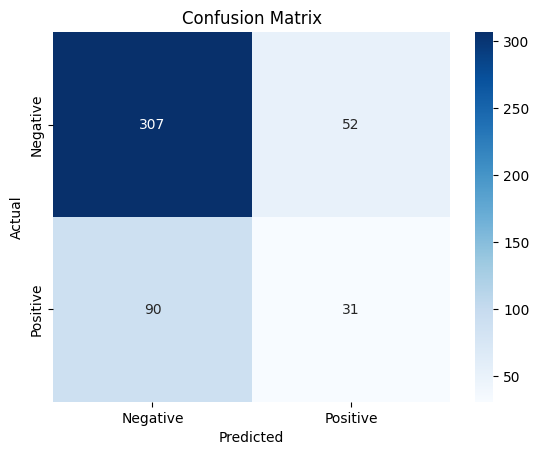

In [67]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

LSTM RNN

In [68]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Embedding
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout

In [69]:
embedding_vector_features=40
max_length=30
voc_size = 5000

model=Sequential()
model.add(Embedding(voc_size,embedding_vector_features,input_length=max_length))
model.add(Dropout(0.3))
model.add(LSTM(32))
model.add(Dropout(0.3))
model.add(Dense(1,activation='sigmoid'))
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
print(model.summary())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [36]:
epochs=5
model.fit(X_train,y_train,validation_data=(X_test,y_test),epochs=epochs,batch_size=64)

Epoch 1/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 169ms/step - accuracy: 0.7146 - loss: 0.6162 - val_accuracy: 0.7479 - val_loss: 0.5706
Epoch 2/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 132ms/step - accuracy: 0.7255 - loss: 0.5905 - val_accuracy: 0.7479 - val_loss: 0.5663
Epoch 3/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step - accuracy: 0.7255 - loss: 0.5947 - val_accuracy: 0.7479 - val_loss: 0.5664
Epoch 4/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 133ms/step - accuracy: 0.7255 - loss: 0.5914 - val_accuracy: 0.7479 - val_loss: 0.5675
Epoch 5/5
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 132ms/step - accuracy: 0.7255 - loss: 0.5921 - val_accuracy: 0.7479 - val_loss: 0.5646


In [70]:
y_pred=model.predict(X_test)
y_pred=np.where(y_pred>0.5,1,0)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step


In [72]:
print(accuracy_score(y_pred,y_test))
print(classification_report(y_pred,y_test))

0.7479166666666667
              precision    recall  f1-score   support

           0       1.00      0.75      0.86       480
           1       0.00      0.00      0.00         0

    accuracy                           0.75       480
   macro avg       0.50      0.37      0.43       480
weighted avg       1.00      0.75      0.86       480



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


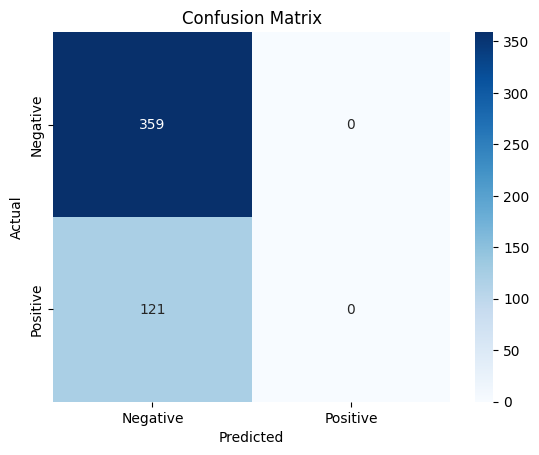

In [73]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

MultinomialNB

In [74]:
lemmatized_sent = []
for i in range(len(corpus)):
  lemmatized_sent.append(corpus[i])

X_train,X_test,y_train,y_test = train_test_split(lemmatized_sent, y, test_size=0.2, random_state=45)

In [75]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
X_train = cv.fit_transform(X_train)
X_test = cv.transform(X_test)

In [76]:
from sklearn.naive_bayes import MultinomialNB

model = MultinomialNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.6020833333333333
              precision    recall  f1-score   support

           0       0.85      0.57      0.68       359
           1       0.35      0.69      0.47       121

    accuracy                           0.60       480
   macro avg       0.60      0.63      0.58       480
weighted avg       0.72      0.60      0.63       480



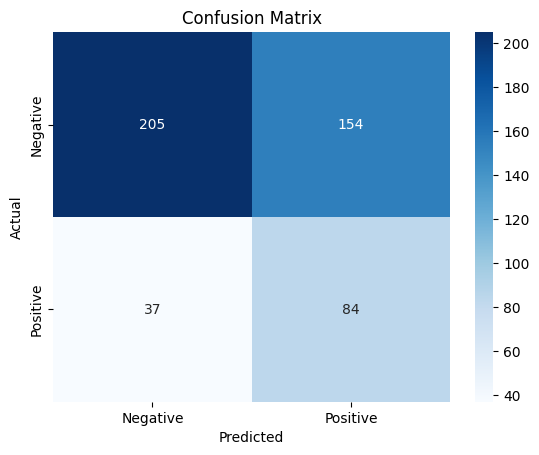

In [77]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

#classification through yt_description


In [44]:
df = df_it[['yt_description','stereotype']]

In [45]:
df.head()

,yt_description,stereotype
0,Nivan è un ragazzo transgender Ftm di soli 17 ...,no
1,"Travolto dalle polemiche, Casillas è stato cos...",no
2,«Sono sempre felice quando c’è il riconoscimen...,yes
3,Dopo che Angela Carini alle Olimpiadi di Parig...,yes
4,Sabato 9 giugno il Roma Pride scende in piazza...,no


In [47]:
sentences=[]
for i in range(len(df['yt_description'])):
  sentence = nltk.sent_tokenize(df['yt_description'][i])
  sentences.append(sentence)
sentences

[['Nivan è un ragazzo transgender Ftm di soli 17 anni.',
  'Vive in un piccolo paesino in provincia di Frosinone insieme al padre Valerio che fin dal primo momento ha accettato e spronato il figlio nella sua scelta di cambiare sesso.',
  '"Quando me l\'ha detto - racconta Valerio - per me è stata la cosa più naturale del mondo andargli incontro e cominciare il cammino insieme a lui senza tanti problemi".',
  "Nivan (un tempo Andrea) è consapevole di essere molto fortunato ad avere l'appoggio della sua famiglia che gli sta permettendo di iniziare il percorso anche se ancora minorenne.",
  '"Io ho paura degli aghi, quindi le punture di testosterone me le fa mio papà - esclama Nivan sorridendo - ed è bravissimo, non mi lascia segni".',
  '- Storie che meritano di essere raccontate.',
  'Ogni giorno.',
  'Tutti i giorni: [URL]'],
 ['Travolto dalle polemiche, Casillas è stato costretto a cancellare il tweet nel quale si dichiarava omosessuale.',
  'Lo aveva scritto per dissimulare il gossip

In [78]:
corpus=[]

stop_words = set(stopwords.words('italian'))

for i in range(len(sentences)):
    full_text = ' '.join(sentences[i])
    review = re.sub('[^a-zA-Zàèéìòù]', ' ', full_text)
    review = review.lower()

    words = word_tokenize(review)
    words = [lemmatize(word, lang='it') for word in words if word not in stop_words]

    corpus.append(' '.join(words))

In [79]:
corpus[1]

'travolgere polemica casillas essere costringere cancellare tweet dichiarare omosessuale scritto dissimulare gossip vita sentimentale pensare modello esempio delusione scherzare cosa colpa hacker scusare messaggio ex portiere casillas annunciare essere gay poi parlare hacker scusa scherzare idiota url rimanere aggiornare url attivare correttamente notifica qualsiasi smartphone url commentare ultimo notizia entrare community url channel giornale indipendente sociale partecipativo seguire live reportage inchiesta storia videonews partecipare informazione rimanere connesso channel facebook url instagram url twitter url tiktok url url'

In [80]:
sent_vectors = []

vector_size = wv_it.get_dimension()

for sentence in corpus:
    vecs = [wv_it[word] for word in sentence.split()]
    if vecs:
        sent_vec = np.mean(vecs, axis=0)
    else:
        sent_vec = np.zeros(vector_size)
    sent_vectors.append(sent_vec)

X = np.array(sent_vectors)

In [81]:
X

array([[ 0.01891615, -0.01385991,  0.00395118, ..., -0.02179315,
         0.0027979 , -0.00566312],
       [ 0.01325981,  0.0109299 ,  0.03325931, ..., -0.02685107,
         0.01309034, -0.00143624],
       [ 0.02496078, -0.00862176,  0.00885732, ..., -0.00629057,
        -0.00113309, -0.01311493],
       ...,
       [ 0.00027345,  0.00202902,  0.05289146, ..., -0.02828402,
         0.00185197, -0.00213731],
       [ 0.01906046,  0.00497586,  0.02455887, ..., -0.03289919,
         0.00939036, -0.00208683],
       [ 0.02849967, -0.01767418,  0.01264638, ..., -0.01086925,
        -0.02281502, -0.00805411]], shape=(2400, 300), dtype=float32)

In [82]:
y = df['stereotype'].map({'no':0,'yes':1})
y.head()

,stereotype
0,0
1,0
2,1
3,1
4,0


In [83]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=45)

In [84]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.75
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       359
           1       1.00      0.01      0.02       121

    accuracy                           0.75       480
   macro avg       0.87      0.50      0.44       480
weighted avg       0.81      0.75      0.64       480



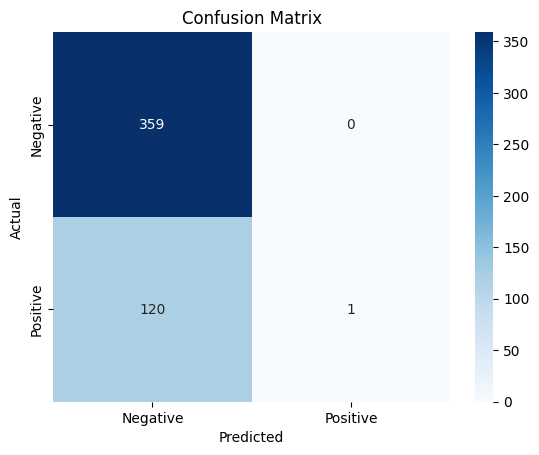

In [85]:
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [86]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test,y_pred))

0.68125
              precision    recall  f1-score   support

           0       0.77      0.82      0.79       359
           1       0.33      0.26      0.29       121

    accuracy                           0.68       480
   macro avg       0.55      0.54      0.54       480
weighted avg       0.66      0.68      0.67       480



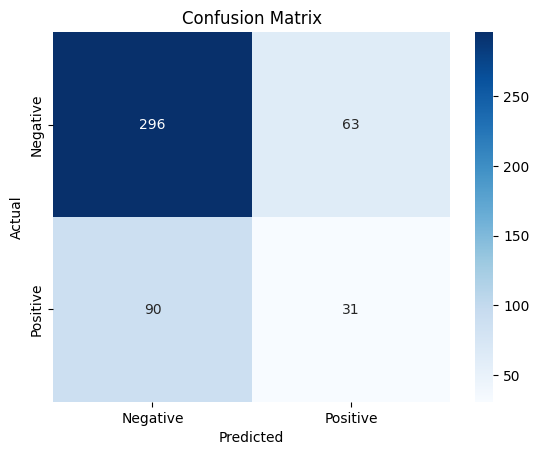

In [87]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()